## DO NOT DO:

Statistical Tests:

Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
Compute Cramér's V to understand the strength of association between best-seller status and category.

Correlation Coefficients:

Calculate the correlation coefficient between price and stars.
Is there a significant correlation between product price and its rating?

---

# IMPORTS

In [8]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

```
⠀⠀⠀⠀⠀⠀⣀⣤⡤⠀⠀⠀
⠀⠀⠀⠀⢀⣾⣿⠋⠀
⠀⠀⠀⣠⣾⣿⡟⠀⠀
⠀⠀⢸⠛⠉⢹⠃⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⢀⡠⠄⠠⣀⠀⠀⠀⠀⠀⠀⠀⠀
⠀⠀⡘⠀⠀⠀⡀⠀⠀⠀⠀⠀⠀⠀⠀⣠⠖⠉⠀⠀⠀⣾⣿⣦⡀⠀⠀⠀⠀⠀
⠀⠀⡇⠀⠀⠀⢡⠄⠀⠀⣀⣀⣀⣠⠊⠀⠀⠀⠀⡠⠞⠛⠛⠛⠛⠀⠀⠀⠀⠀
⠀⠀⢃⠀⠀⠀⠀⠗⠚⠉⠉⠀⠈⠁⠀⠀⠀⢀⡔⠁⠀
⠀⠀⠸⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⣴⣶⣄⠲⡎⠀⠀
⠀⠀⠀⠃⠀⠀⢠⣤⡀⠀⠀⠀⠀⣿⣿⣿⠀⠘⡄
⠀⠀⠀⡆⠀⠀⣿⣿⡇⠀⠀⠀⠀⠈⠛⠉⣴⣆⢹⡄⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀
⠀⠀⠀⣇⢰⡧⣉⡉⠀⠀⢀⡀⠀⣀⣀⣠⣿⡷⢠⡇⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀
⠀⠀⠀⢻⠘⠃⠈⠻⢦⠞⠋⠙⠺⠋⠉⠉⠉⢡⠟⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀
⠀⠀⠀⠀⠳⢄⡀⠀⠀⠀⠀⠀⠀⠀⠀⠀⢠⠋⠀⠀
```

In [2]:
# Matplotlib inline to visualize Matplotlib graphs
%matplotlib inline

# Configuration to set so that all the Seaborn figures come out with this size
%config Inlinebackend.figure_format= 'retina'

In [3]:
# Set the Seaborn context to "poster" for larger text and figures
sns.set_context("poster")

# Set the default figure size for Seaborn plots
sns.set(rc={"figure.figsize": (12., 6.)})

# Set the Seaborn style to "whitegrid" for a white background with gridlines
sns.set_style("whitegrid")

---

# DATAFRAME

In [6]:
path= "data/amz_uk_price_prediction_dataset.csv"

In [11]:
data= pd.read_csv(path)

In [12]:
df= pd.DataFrame(data)

In [13]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


---
### Part 1: Analyzing Best-Seller Trends Across Product Categories

**Objective**: Understand the relationship between product categories and their best-seller status.

1. **Crosstab Analysis**:
    - Create a crosstab between the product `category` and the `isBestSeller` status.
    
    - Are there categories where being a best-seller is more prevalent? 
    	
    	*Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.*


2. **~~Statistical Tests~~**:
   - ~~Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.~~
   - ~~Compute Cramér's V to understand the strength of association between best-seller status and category.~~


3. **Visualizations**:
	- Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

---

In [ ]:
# Creating a crosstab between <category> and <isBestSeller>
# ct= category_bestseller_crosstab

ct= pd.crosstab(df["category"], df["isBestSeller"])
ct.sample(5)

isBestSeller,False,True
category,,
Furniture & Lighting,9145,27
Coffee & Espresso Machines,510,4
Building & Construction Toys,9481,9
Tennis Shoes,4684,1
"Water Coolers, Filters & Cartridges",186,1


### **Are there categories where being a best-seller is more prevalent?**

We can see it if we made a really quick search while sorting the dataframe and seeing the first 5 elements with .head()

In [ ]:
# Proportion of best-sellers in each category
ct_proportion= ct[True]/ ct.sum(axis=1)
ct_proportion.sort_values(ascending= False)

category
Grocery                             0.058135
Smart Home Security & Lighting      0.057692
Health & Personal Care              0.057686
Mobile Phone Accessories            0.042471
Power & Hand Tools                  0.035339
                                      ...   
CD, Disc & Tape Players             0.000000
General Music-Making Accessories    0.000000
Snowboard Boots                     0.000000
Boxes & Organisers                  0.000000
eBook Readers & Accessories         0.000000
Length: 296, dtype: float64

In [26]:
# Converting proportios into percentage
ct_proportion_percentage= ct_proportion.sort_values(ascending=False) * 100 

In [27]:
ct_proportion_percentage.round(2)

category
Grocery                             5.81
Smart Home Security & Lighting      5.77
Health & Personal Care              5.77
Mobile Phone Accessories            4.25
Power & Hand Tools                  3.53
                                    ... 
CD, Disc & Tape Players             0.00
General Music-Making Accessories    0.00
Snowboard Boots                     0.00
Boxes & Organisers                  0.00
eBook Readers & Accessories         0.00
Length: 296, dtype: float64

---

### In order to conduct a Chi-square, we need to import chi2_contingency

In [33]:
from scipy.stats import chi2_contingency

In [41]:
_, chi2_pvalue, _, _  = chi2_contingency(ct)
a,b,c,d=chi2_contingency(ct)
print(f"P-value: {chi2_pvalue:.5f}")

P-value: 0.00000


In this case, the P-value is really near to 0 (or zero) so this is indicating a strong statistical association between the two variables. This means the likelihood of a product being a best-seller depends significantly on its category.

### In order to compute Cramér's V, we need to import association

In [42]:
from scipy.stats.contingency import association

In [45]:
print(f"Cramér's value: {association(ct, method='cramer'):.5f}")

Cramér's value: 0.12228


### Cramér’s V Interpretation Guide (Cohen's Conventions)

| Cramér’s V | Strength of Association   |
|------------|----------------------------|
| 0.00–0.10  | Negligible / Very Weak     |
| 0.10–0.20  | Weak                       |
| 0.20–0.30  | Moderate                   |
| 0.30–0.50  | Strong                     |
| > 0.50     | Very Strong                |


### **P-value:**
The p-value measures the probability of observing the data if the null hypothesis is true. A small p-value (typically < 0.05) suggests that the null hypothesis can be rejected. It demonstrates whether there is a statistically significant association between variables. In our exercise, the p-value near zero indicates that product category and best-seller status are not independent.

### **Cramér's V:**
Cramér's V quantifies the strength of association between two categorical variables, ranging from 0 (no association) to 1 (perfect association). It demonstrates how strongly the variables are related, not just whether they are associated. In our exercise, a Cramér's V of 0.12 indicates a weak association between category and best-seller status.

---

### Let's visualizate this better in a plot:

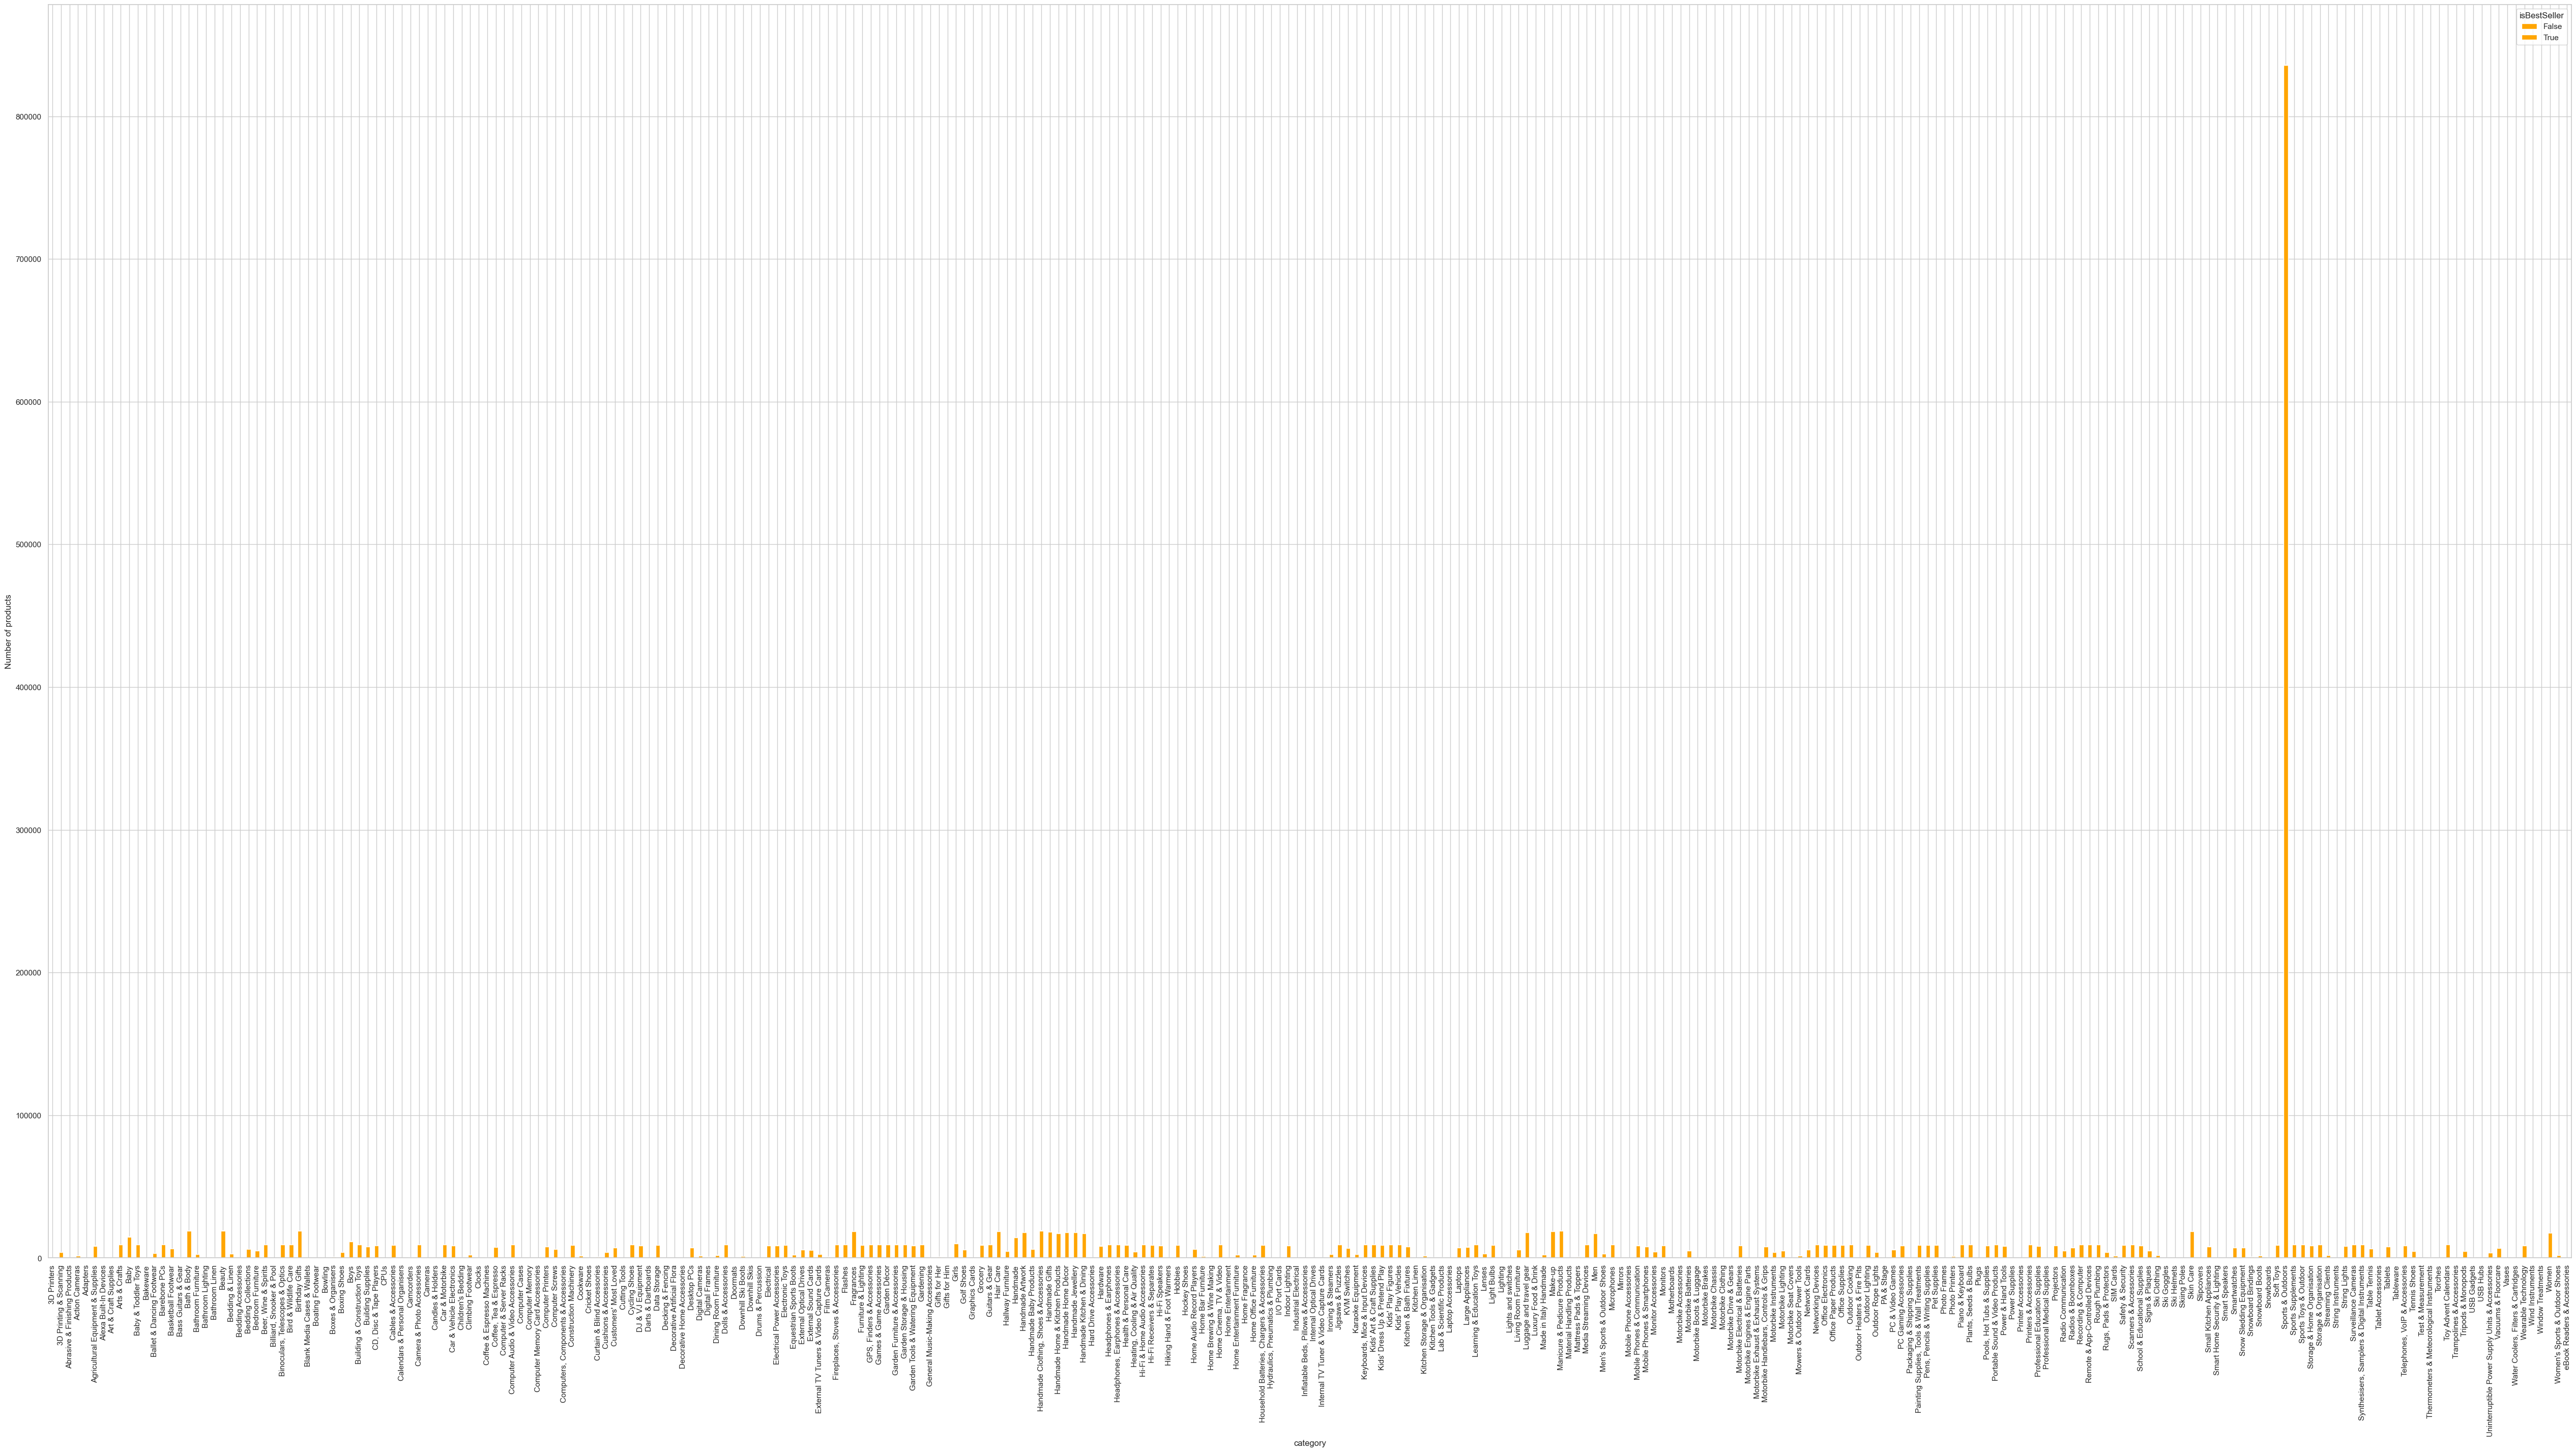

In [69]:
ct.plot(kind= "bar", stacked=True, figsize= (64, 32), color= "orange") #make it bigger makes it lttle bit more redable
plt.ylabel("Number of products")
plt.show()

### Plot 1: Product Count by Category (Stacked Bar)
- BestSeller products (orange) are extremely rare across all categories.
- Most categories have only non-BestSeller items (blue), with one category dominating total product count.
- Visualization is cluttered due to too many categories; top 10–20 would improve readability.
---

### Part 2: Exploring Product Prices and Ratings Across Categories and Brands

**Objective**: Investigate how different product categories influence product prices.

0. **Preliminary Step: Remove outliers in product prices.**

	For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.
	
	*Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.*

1. **Violin Plots**:
    - Use a violin plot to visualize the distribution of `price` across different product `categories`. Filter out the top 20 categories based on count for better visualization.
    - Which product category tends to have the highest median price? Don't filter here by top categories.

2. **Bar Charts**:
    - Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
    - Which product category commands the highest average price? Don't filter here by top categories.

3. **Box Plots**:
    - Visualize the distribution of product `ratings` based on their `category` using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
    - Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

---

In [46]:
# Removing the outliers

Q1= df["price"].quantile(0.25)
Q3= df["price"].quantile(0.75)

IQR= Q3 - Q1

In [ ]:
IQR

36.0

The IQR measures the middle 50% of the data (Q3 − Q1).
Values below Q1 − 1.5×IQR or above Q3 + 1.5×IQR are considered outliers.

In [49]:
lower_bound= Q1 - 1.5 * IQR
upper_bound= Q3 + 1.5 * IQR

In [50]:
print(f"Lower bound: {lower_bound}\nUpper bound: {upper_bound}")

Lower bound: -44.01
Upper bound: 99.99000000000001


Using the IQR method, prices below −44.01 or above 99.99 are considered outliers. These extreme values are removed to focus the analysis on typical product prices. This ensures that visualizations and summary statistics are not skewed by unusually low or high prices.

We are gonna use a new dataframe that is the very same but without the outliers we have definied

In [51]:
df_no_outliers= df[(df['price'] >= lower_bound) & (df['price'] <= upper_bound)]
df_no_outliers.sample(5)

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
434505,466996,B0CDKN5XK8,SRTUMEY Clearance Sweater Babys Newborn Infant...,0.0,0,11.29,False,0,Sports & Outdoors
1270676,1406308,B0B92VL4JY,Perfeclan 6Pcs Key Rings Float Pendant Buoyant...,0.0,0,10.99,False,0,Sports & Outdoors
75632,81918,B0CJ5Q1CF9,Famous YouTube Gamer Boys Girls Jumper Lightni...,0.0,0,12.99,False,0,Boys
812105,886534,B012WWVJ30,AZ FLAG Plain Yellow Flag 18'' x 12'' cords - ...,3.7,31,6.95,False,0,Garden Décor
2326787,2682349,B08QMM64WN,"DGO Light Bulb, G40 Screw Light Bulbs, E12 Edi...",4.5,192,11.99,False,50,Light Bulbs


In [62]:
# Violin plot in top(20) categories

df_top20_cats= df_no_outliers["category"].value_counts().head(20).index
df_top20= df_no_outliers[df_no_outliers['category'].isin(df_top20_cats)]
df_top20.sample(5)

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
774111,834987,B0BJCYT44Q,Mascara & Muscles Water Bottle Lash Extensions...,0.0,0,5.49,False,0,Sports & Outdoors
1439764,1583281,B0BWDMNDFG,PYNQ Yoga Pillow Washable Polyester Rectangula...,0.0,0,16.05,False,0,Sports & Outdoors
1471543,1627281,B095CHTLCL,Astemdhj Leggings Fitness pants Fitness Leggin...,0.0,0,34.99,False,0,Sports & Outdoors
513482,552478,B0C43JLY96,Women’s 2 Pieces Skirt with Cold Shoulder High...,0.0,0,15.38,False,0,Sports & Outdoors
512987,551960,B0CGD7CNP1,MKIUHNJ Sweaters Slim Fashion Warm Padded Outw...,0.0,0,38.50,False,0,Sports & Outdoors


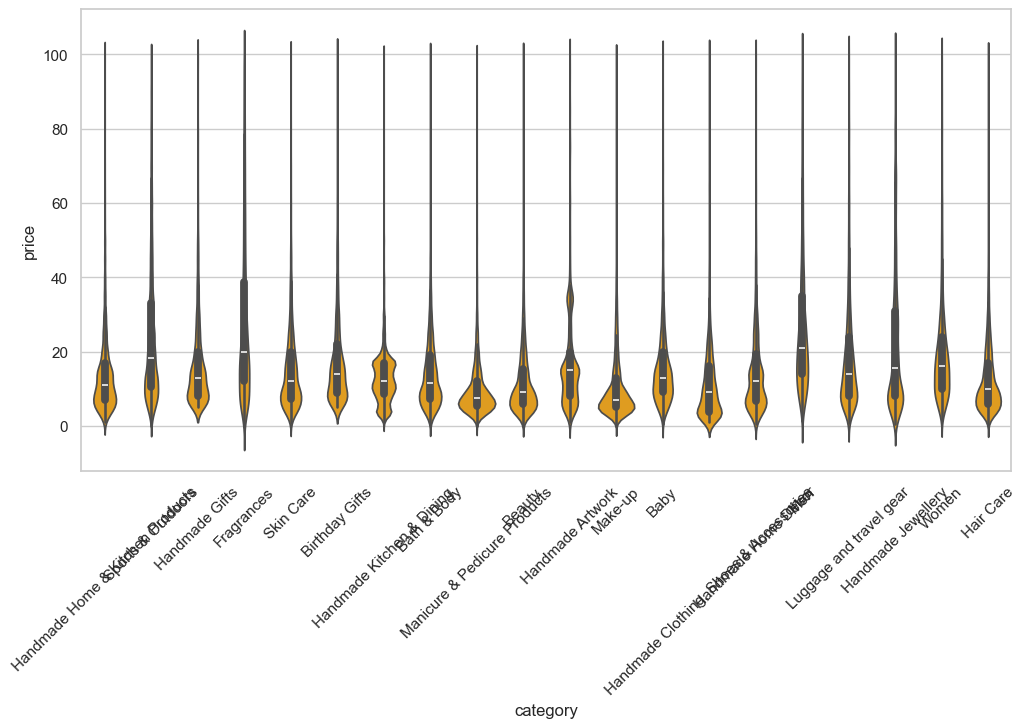

In [71]:
sns.violinplot(x= "category", y= "price", data= df_top20, color= "orange")
plt.xticks(rotation= 45)
plt.show()

### Plot 2: Price Distribution by Category (Violin)
- Prices are skewed low in most categories, with median under $20.
- “Handmade Artwork” and “Make-up” show wider price ranges; “Sports & Outdoors” has the highest outliers.
- Most categories have similar central tendency but differ in spread and tail behavior.
---

In [61]:
# Bar chart in top(10) categories
top_10_cats= df_no_outliers["category"].value_counts().head(10).index
df_top10= df_no_outliers[df_no_outliers["category"].isin(top_10_cats)]
df_top10.sample(5)

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
894748,973752,B0CF2ND5W1,Ansenesna Men's Sportstyle Graphic Crewneck Sw...,0.0,0,5.96,False,0,Sports & Outdoors
1520530,1706924,B0CF2C42L5,Women's 2 Piece Set Outfits Spring Casual Shor...,0.0,0,14.63,False,0,Sports & Outdoors
1865078,2094494,B0C1N2HMP7,"Botoxlux Collagen Anti Aging Serum,Collagen Bo...",3.8,22,8.09,False,100,Beauty
1273217,1409077,B0B434TMY6,UIKEEYUIS Pack of 10 Kayak Eyelet Tie Down Loo...,0.0,0,7.59,False,0,Sports & Outdoors
1214324,1341003,B0B6W31Q2P,GZDD Professional Road Cycling Shoes Mtb Bike ...,0.0,0,59.99,False,0,Sports & Outdoors


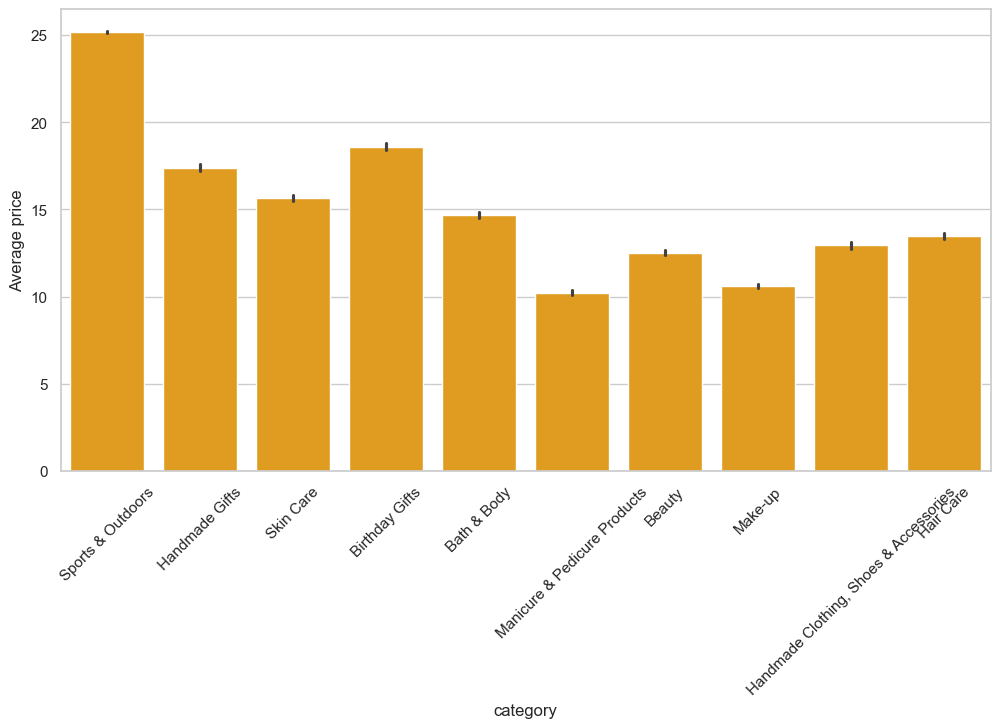

In [72]:
sns.barplot(x="category", y="price", data= df_top10, estimator= np.mean, color= "orange")
plt.xticks(rotation= 45)
plt.ylabel("Average price")
plt.show()

### Plot 3: Average Price by Category (Bar)
- “Sports & Outdoors” has the highest average price (~$25), followed by “Birthday Gifts” (~$19).
- “Manicure & Pedicure Products” has the lowest average price (~$10).
- All other categories cluster between $12–$18, indicating moderate pricing consistency.
---

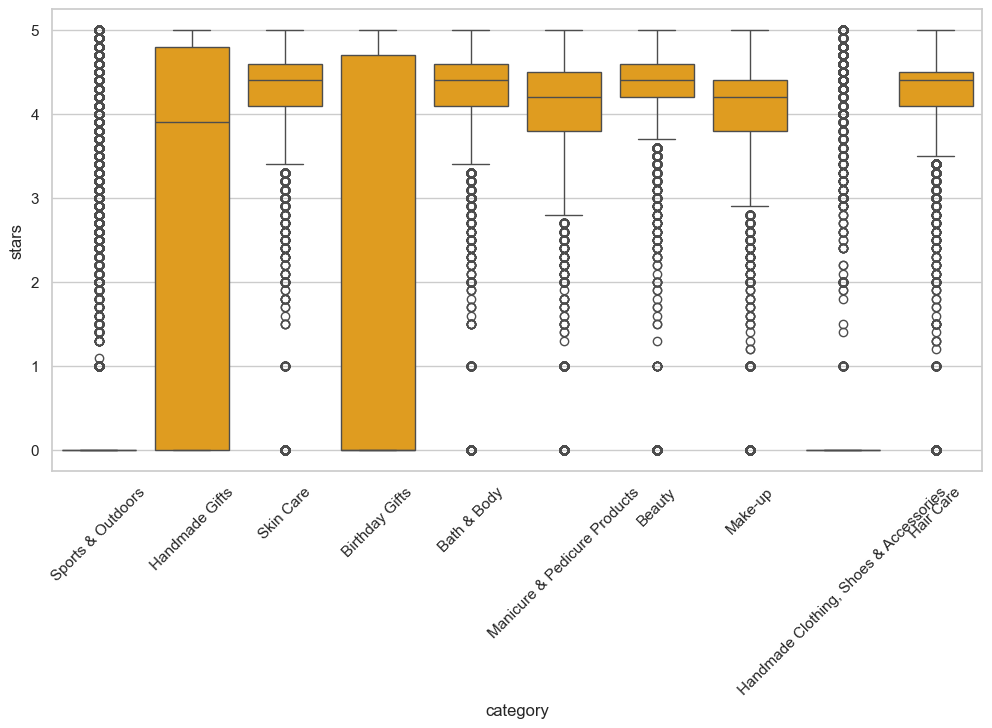

In [73]:
# Boxplot using top(10) categories

sns.boxplot(x= "category", y= "stars", data= df_top10, color= "orange")
plt.xticks(rotation= 45)
plt.show()

### Plot 4: Stars Rating by Category (Boxplot)
- “Sports & Outdoors” has the widest rating range and many outliers, suggesting polarized reviews.
- “Handmade Gifts” and “Birthday Gifts” show high median ratings (~4.5) with tight IQRs.
- Several categories (e.g., “Make-up”, “Hair Care”) have low medians (~1.0), indicating poor customer satisfaction.
---